# Phase 4 - ensembles and the final test-set evaluation (Parts G and H)

**Question.** Which two models should be combined, does the ensemble help, and which model do we recommend?

**Brief and report.** Parts G and H. Report Sections 7–8.

**The test set.** This is the only notebook that uses it, and only once, after every choice had been fixed on training CV.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

### 1. Choose the pair, build the ensembles, evaluate once
`run_evaluation()` in `src/evaluate.py` works in five steps:
1. Pick the two models with the best tuned CV AP.
2. Build soft voting (an equal average of their probabilities) and stacking (a logistic regression trained on their out-of-fold probabilities).
3. Apply the recommendation rule fixed in advance: the simplest model within 0.001 CV AP of the best.
4. Only then load the test set and score every model.
5. Save the recommended model to `models/`.

**How to read the output.** `metrics` is the test-set table (report Table 14). `efficiency` gives fit time, scoring time and size on disk.

In [2]:
from src.evaluate import run_evaluation
metrics, efficiency, errors, fairness = run_evaluation()
display(metrics)
display(efficiency)

Phase 4 | out-of-fold: Logistic Regression: OOF AP 0.628


Phase 4 | out-of-fold: Random Forest: OOF AP 0.689


Phase 4 | out-of-fold: Hist Gradient Boosting: OOF AP 0.687


Phase 4 | ensemble CV: Voting: AP 0.694


Phase 4 | ensemble CV: Stacking: AP 0.694


Phase 4 | recommendation fixed: pair ['Random Forest', 'Hist Gradient Boosting']; recommended Voting (before test access).


... (6 outputs left out)

Phase 4 | test result: Voting: AP 0.698, F1 0.591


Phase 4 | test result: Stacking: AP 0.698, F1 0.595


,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,Majority baseline,0.729,0.500,0.000,0.000,0.000,0.500,0.271
1,Stratified baseline,0.603,0.498,0.267,0.269,0.268,0.498,0.270
2,Logistic Regression,0.795,0.677,0.706,0.419,0.526,0.787,0.633
3,Random Forest,0.811,0.716,0.714,0.507,0.593,0.835,0.696
4,Hist Gradient Boosting,0.808,0.709,0.710,0.493,0.582,0.833,0.689
5,Voting,0.812,0.714,0.721,0.501,0.591,0.838,0.698
6,Stacking,0.812,0.717,0.716,0.510,0.595,0.838,0.698


,model,fit_seconds,predict_seconds_per_1000,model_size_kib
0,Majority baseline,1.045,0.005,6.380
1,Stratified baseline,1.012,0.004,6.380
2,Logistic Regression,2.756,0.006,7.237
3,Random Forest,40.928,0.051,49894.476
4,Hist Gradient Boosting,22.458,0.056,1325.940
5,Voting,61.032,0.108,51208.752
6,Stacking,314.945,0.107,51217.701


### 2. Evidence behind the choice
These tables explain the choice and test it:
- why logistic regression was left out (base-model selection, pair diversity)
- training, CV and test scores side by side (overfitting)
- confusion matrices

In [3]:
for name in ['phase4_base_model_selection.csv', 'phase4_pair_diversity.csv', 'phase4_model_cv.csv', 'phase4_overfitting.csv', 'phase4_confusion_matrices.csv']:
    display(Markdown(f'**results/{name}**'))
    display(results(name))
import json
display(json.loads((ROOT / 'results/phase4_ensemble_selection.json').read_text(encoding='utf-8')))

**results/phase4_base_model_selection.csv**

,model,tuned_pr_auc,pr_auc_std,selected
0,Random Forest,0.690,0.007,True
1,Hist Gradient Boosting,0.687,0.006,True
2,Logistic Regression,0.628,0.005,False


**results/phase4_pair_diversity.csv**

,first,second,probability_correlation,error_correlation,disagreement,both_wrong,selected_pair
0,Logistic Regression,Random Forest,0.824,0.746,0.082,0.162,False
1,Logistic Regression,Hist Gradient Boosting,0.868,0.796,0.066,0.170,False
2,Random Forest,Hist Gradient Boosting,0.958,0.873,0.040,0.174,True


**results/phase4_model_cv.csv**

,model,pr_auc_mean,pr_auc_std,train_pr_auc_mean,accuracy_mean,accuracy_std,train_accuracy_mean,balanced_accuracy_mean,balanced_accuracy_std,train_balanced_accuracy_mean,precision_mean,precision_std,train_precision_mean,recall_mean,recall_std,train_recall_mean,f1_mean,f1_std,train_f1_mean,roc_auc_mean,roc_auc_std,train_roc_auc_mean,fit_seconds,fit_seconds_std
0,Random Forest,0.690,0.007,0.977,0.806,0.004,0.939,0.710,0.004,0.901,0.711,0.006,0.958,0.497,0.006,0.815,0.585,0.005,0.881,0.831,0.003,0.991,41.356,NaN
1,Hist Gradient Boosting,0.687,0.006,0.785,0.806,0.005,0.830,0.709,0.005,0.742,0.714,0.008,0.774,0.494,0.008,0.544,0.584,0.008,0.639,0.831,0.002,0.895,20.736,NaN
2,Logistic Regression,0.628,0.005,0.631,0.789,0.002,0.790,0.674,0.003,0.675,0.695,0.010,0.699,0.417,0.007,0.418,0.521,0.005,0.523,0.784,0.004,0.786,3.248,NaN
3,Voting,0.694,0.006,0.913,0.806,0.004,0.879,0.710,0.004,0.811,0.715,0.006,0.871,0.495,0.007,0.659,0.585,0.007,0.751,0.835,0.002,0.964,63.068,0.674
4,Stacking,0.694,0.006,0.915,0.807,0.004,0.882,0.712,0.004,0.818,0.713,0.006,0.870,0.502,0.008,0.675,0.589,0.007,0.760,0.834,0.003,0.965,336.346,3.189


**results/phase4_overfitting.csv**

,model,train_pr_auc,cv_pr_auc,cv_pr_auc_std,test_pr_auc,train_minus_cv,cv_minus_test
0,Logistic Regression,0.630,0.628,0.005,0.633,0.002,-0.005
1,Random Forest,0.975,0.690,0.007,0.696,0.285,-0.007
2,Hist Gradient Boosting,0.772,0.687,0.006,0.689,0.085,-0.001
3,Voting,0.906,0.694,0.006,0.698,0.212,-0.004
4,Stacking,0.919,0.694,0.006,0.698,0.225,-0.004


**results/phase4_confusion_matrices.csv**

,model,tn,fp,fn,tp
0,Majority baseline,12775,0,4744,0
1,Stratified baseline,9283,3492,3469,1275
2,Logistic Regression,11946,829,2757,1987
3,Random Forest,11812,963,2340,2404
4,Hist Gradient Boosting,11821,954,2403,2341
5,Voting,11854,921,2369,2375
6,Stacking,11816,959,2326,2418


{'pair': ['Random Forest', 'Hist Gradient Boosting'],
 'excluded': 'Logistic Regression',
 'recommended': 'Voting',
 'rule': 'simplest model within 0.001 of the best training-CV AP; ties favour higher AP',
 'primary_metric': 'average_precision',
 'threshold': 0.5,
 'test_used_for_selection': False}

### 3. Where the model fails, and for whom
- errors by lead time, hotel, market segment and customer type
- the profile of the cancellations it misses
- an audit of errors by guest country (country is not a model input)

Then all the evaluation figures.

,field,group,rows,cancel_rate,recall,precision,false_negatives,false_positives,pr_auc
0,lead time (days),0-7,3717,0.084,0.086,0.871,287,4,0.352
1,lead time (days),31-90,4552,0.315,0.478,0.686,748,313,0.659
2,lead time (days),8-30,3282,0.244,0.395,0.712,484,128,0.631
3,lead time (days),91-180,3637,0.347,0.561,0.713,553,285,0.724
4,lead time (days),181-365,2218,0.404,0.682,0.765,285,187,0.829
5,lead time (days),>365,113,0.363,0.707,0.879,12,4,0.901
6,hotel,Resort Hotel,6859,0.234,0.446,0.719,889,279,0.664
7,hotel,City Hotel,10660,0.295,0.529,0.721,1480,642,0.714
8,market segment,Direct,2356,0.144,0.121,0.820,299,9,0.447
9,market segment,Offline TA/TO,2716,0.142,0.190,0.869,312,11,0.491


,outcome,rows,median_lead_time,median_adr,mean_requests,share_prior_cancellation,share_online_ta,share_groups,share_city_hotel
0,caught cancellation,2375,108.0,114.3,0.246,0.106,0.869,0.070,0.699
1,correct non-cancellation,11854,33.0,91.6,0.782,0.008,0.491,0.062,0.580
2,false alarm,921,93.0,117.0,0.316,0.012,0.953,0.016,0.697
3,missed cancellation,2369,59.0,105.0,0.843,0.003,0.642,0.054,0.625


,country_group,rows,cancel_rate,flagged_rate,recall,false_positive_rate,precision,pr_auc
0,PRT,5467,0.359,0.148,0.361,0.029,0.874,0.769
1,GBR,2097,0.194,0.168,0.562,0.074,0.646,0.672
2,FRA,1794,0.185,0.175,0.547,0.091,0.576,0.577
3,ESP,1422,0.250,0.179,0.521,0.065,0.728,0.687
4,DEU,1107,0.199,0.207,0.614,0.106,0.590,0.598
5,Other,5632,0.261,0.237,0.638,0.096,0.702,0.731


**reports/figures/fig_G_01_oof_diversity.png**

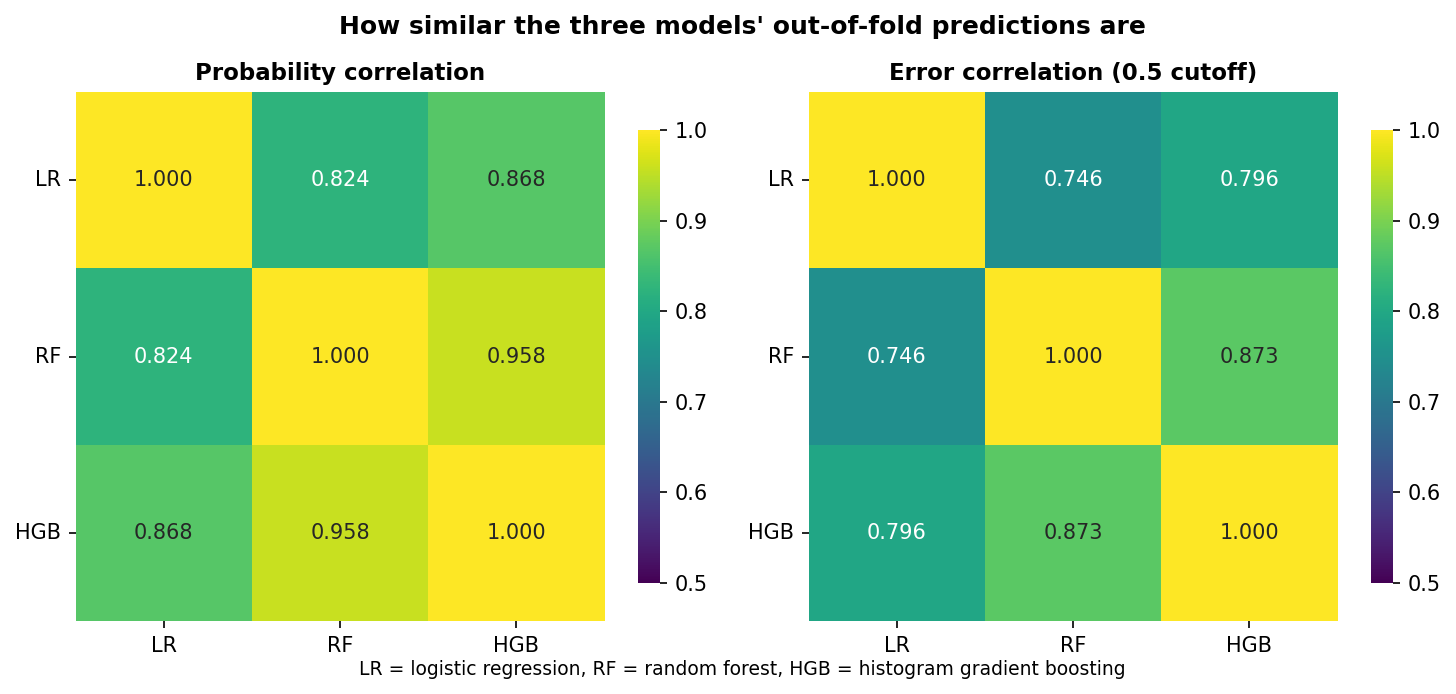

**reports/figures/fig_H_01_confusion_matrices.png**

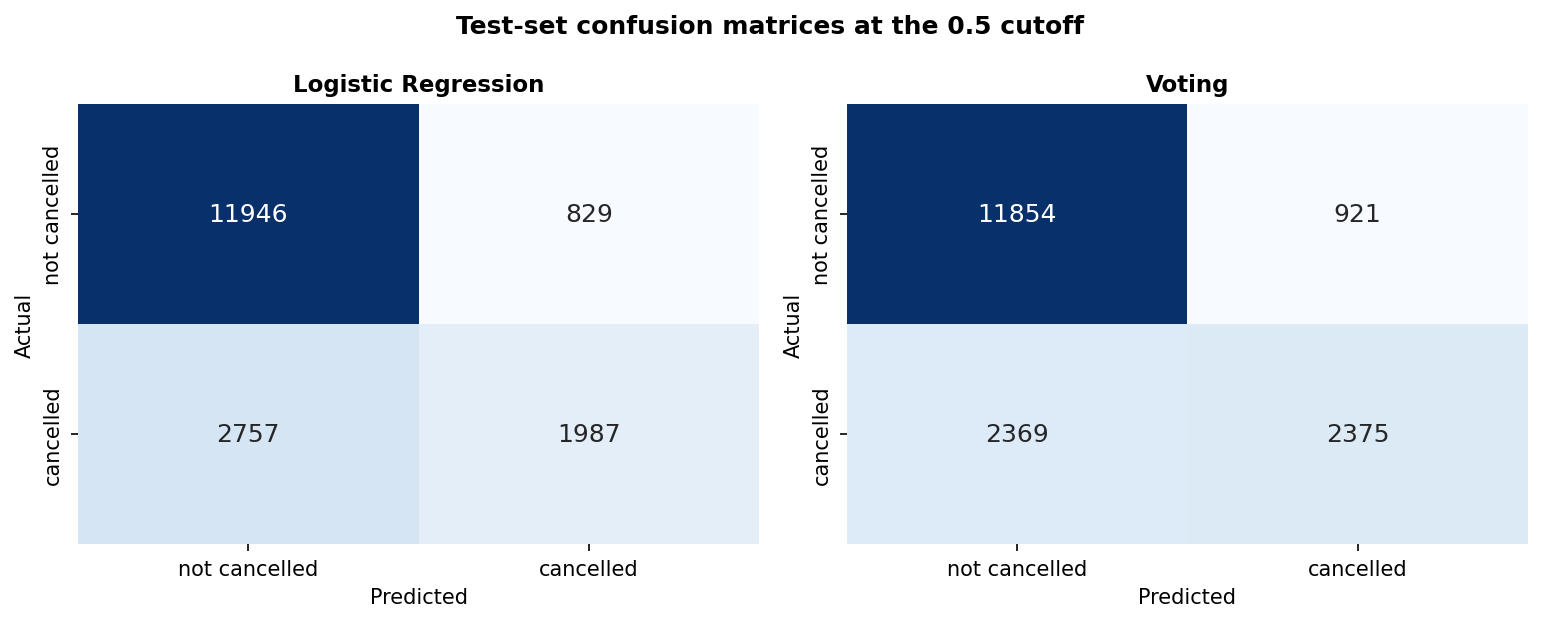

**reports/figures/fig_H_02_roc_curves.png**

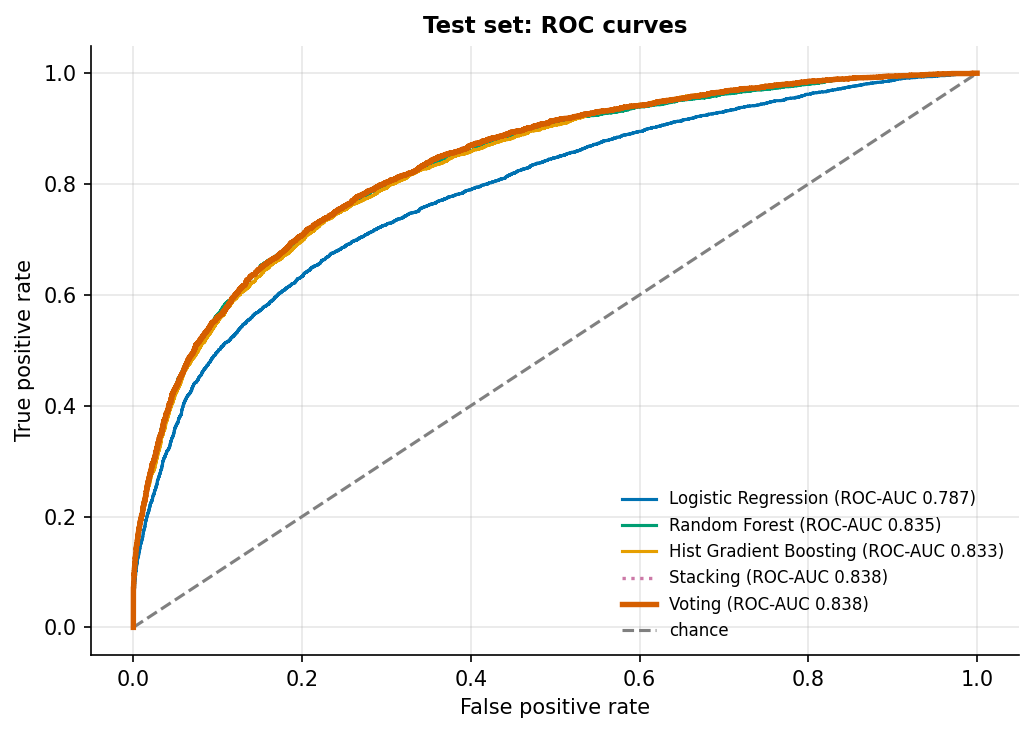

**reports/figures/fig_H_03_pr_curves.png**

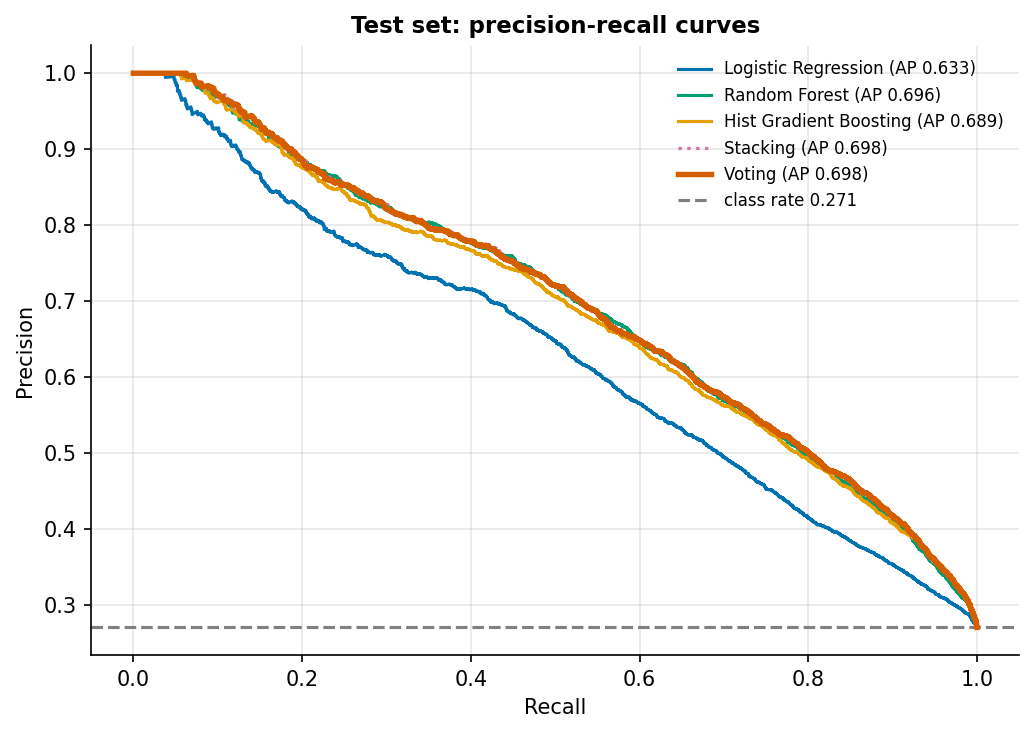

**reports/figures/fig_H_07_errors_by_lead_time.png**

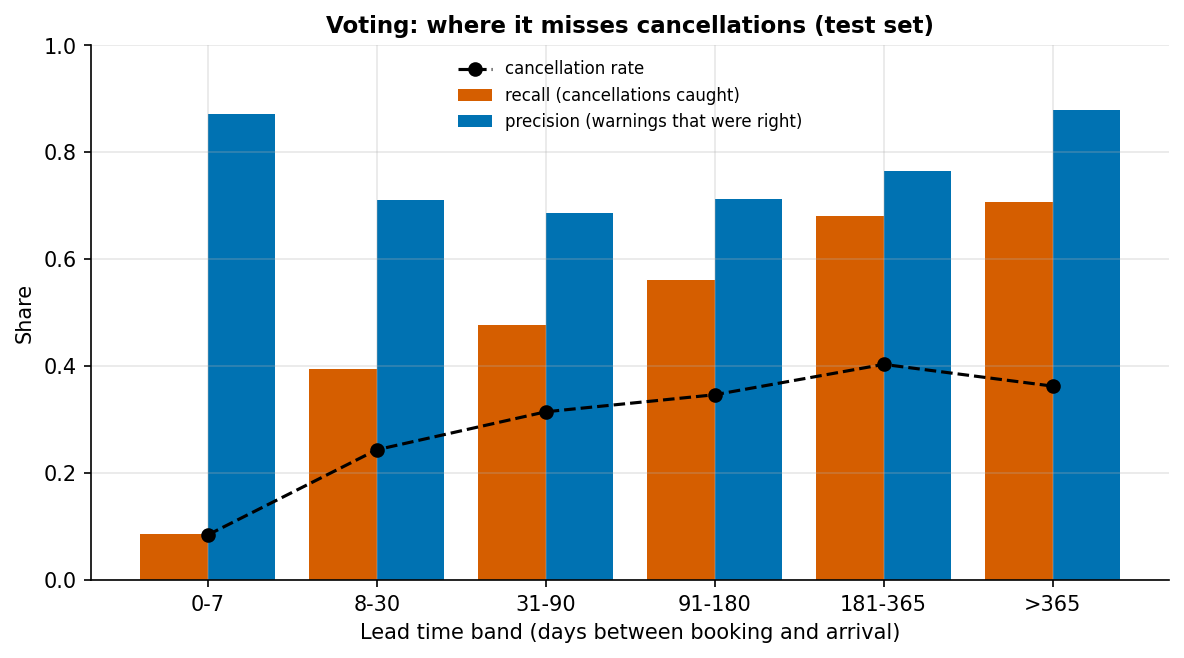

**reports/figures/fig_H_08_fairness_country.png**

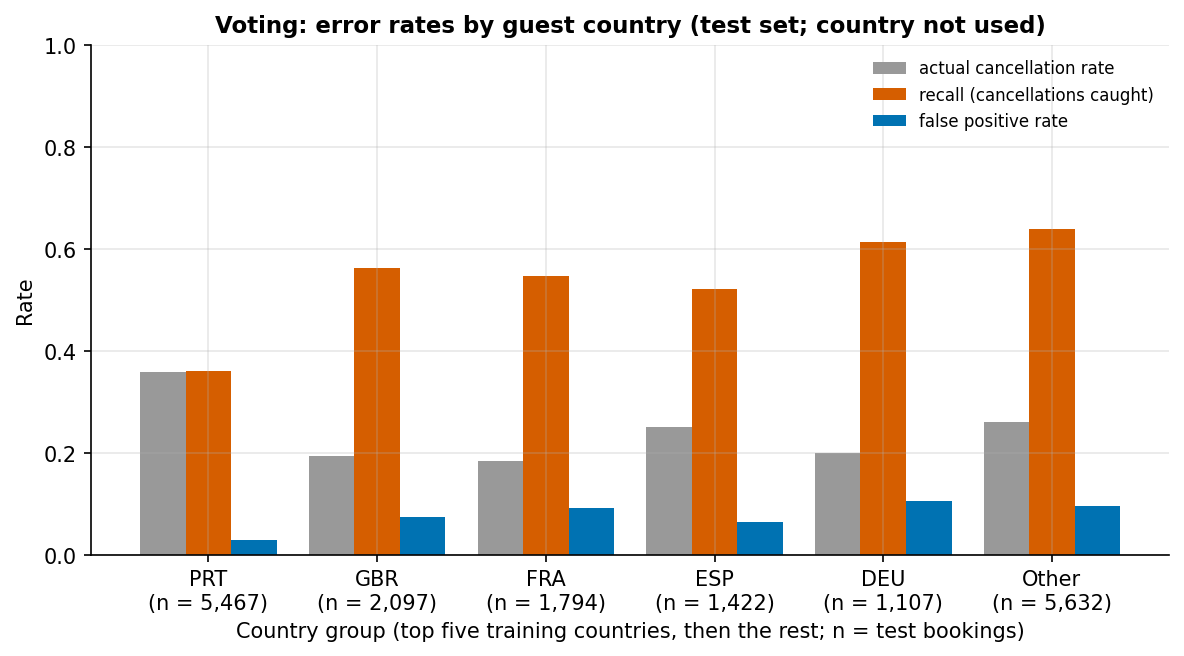

In [4]:
display(errors)
display(results('phase4_error_profile.csv'))
display(fairness)
show('fig_G_01_oof_diversity.png', 'fig_H_01_confusion_matrices.png', 'fig_H_02_roc_curves.png', 'fig_H_03_pr_curves.png', 'fig_H_07_errors_by_lead_time.png', 'fig_H_08_fairness_country.png')